# Notebook 02 — Reproducible FD001 Baseline

**Project:** Self-Healing Machines: Predictive Maintenance for a Connected Fleet  
**Dataset:** NASA C-MAPSS FD001  
**Goal:** Reproduce a Random Forest baseline with a leakage-safe engine-level validation split and evaluate one prediction per held-out engine at the 80% observation cutoff.

## Important choices

- Split by **engine ID**, not by individual rows, so the same engine cannot appear in both training and validation.
- Fit the model on training engines only.
- Use the final 80%-cutoff observation from each validation engine for evaluation.
- Treat **RUL cap = 150** as a candidate configuration based on the previous exploration, not a universally optimal value.
- Do not use the official test labels for further model selection.

Run this notebook from top to bottom in a fresh kernel.


## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
RUL_CAP = 150
OBSERVATION_FRACTION = 0.80


## 2. Locate the project and load FD001 training data

This cell searches upward from the current notebook directory for the expected project structure, so it works when launched from the project root or the `notebooks/` directory.

In [2]:
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        expected = (
            candidate / "data" / "raw" / "train" / "train_FD001.txt",
            candidate / "data" / "raw" / "train_FD001.txt",
        )
        if any(path.exists() for path in expected):
            return candidate
    raise FileNotFoundError(
        "Could not locate train_FD001.txt. Expected it under "
        "'data/raw/train/' or 'data/raw/'. Check the project directory."
    )

PROJECT_ROOT = find_project_root()
TRAIN_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw" / "train" / "train_FD001.txt",
    PROJECT_ROOT / "data" / "raw" / "train_FD001.txt",
]
TRAIN_PATH = next((p for p in TRAIN_CANDIDATES if p.exists()), None)

if TRAIN_PATH is None:
    raise FileNotFoundError("Training file not found in expected locations.")

print("Project root:", PROJECT_ROOT)
print("Training file:", TRAIN_PATH)


Project root: /home/rupali-jha/machine-life-predictor
Training file: /home/rupali-jha/machine-life-predictor/data/raw/train/train_FD001.txt


In [3]:
column_names = (
    ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_df = pd.read_csv(
    TRAIN_PATH,
    sep=r"\s+",
    header=None,
    names=column_names,
)

print("Shape:", train_df.shape)
print("Engines:", train_df["engine_id"].nunique())
display(train_df.head())


Shape: (20631, 26)
Engines: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 3. Basic data checks

In [4]:
print("Missing values:", int(train_df.isna().sum().sum()))
print("Duplicate rows:", int(train_df.duplicated().sum()))
print("Rows per engine (first few):")
display(train_df.groupby("engine_id").size().head())


Missing values: 0
Duplicate rows: 0
Rows per engine (first few):


engine_id
1    192
2    287
3    179
4    189
5    269
dtype: int64

## 4. Construct RUL labels

For each training observation, the target is the engine's last observed training cycle minus the current cycle. We also create a capped target for the candidate experiment.

In [5]:
max_cycle_by_engine = train_df.groupby("engine_id")["cycle"].transform("max")
train_df = train_df.copy()
train_df["RUL"] = max_cycle_by_engine - train_df["cycle"]
train_df["RUL_capped"] = train_df["RUL"].clip(upper=RUL_CAP)

display(train_df[["engine_id", "cycle", "RUL", "RUL_capped"]].head())
print("RUL range:", int(train_df["RUL"].min()), "to", int(train_df["RUL"].max()))


,engine_id,cycle,RUL,RUL_capped
0,1,1,191,150
1,1,2,190,150
2,1,3,189,150
3,1,4,188,150
4,1,5,187,150


RUL range: 0 to 361


## 5. Select features and split by engine

The feature list below follows the exploration notebook: constant columns are excluded. The split is made on unique engine IDs first, then rows are assigned based on those IDs.

In [6]:
feature_columns = [
    "cycle",
    "setting_1",
    "setting_2",
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_6",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21",
]

engine_ids = train_df["engine_id"].unique()
train_engine_ids, val_engine_ids = train_test_split(
    engine_ids,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

train_mask = train_df["engine_id"].isin(train_engine_ids)
val_mask = train_df["engine_id"].isin(val_engine_ids)

X_train = train_df.loc[train_mask, feature_columns]
y_train = train_df.loc[train_mask, "RUL_capped"]

val_df = train_df.loc[val_mask].copy()

print(f"Training engines: {len(train_engine_ids)}")
print(f"Validation engines: {len(val_engine_ids)}")
print("Engine overlap:", len(set(train_engine_ids) & set(val_engine_ids)))
print("Training rows:", len(X_train))
print("Validation rows:", len(val_df))


Training engines: 80
Validation engines: 20
Engine overlap: 0
Training rows: 16561
Validation rows: 4070


## 6. Train the baseline Random Forest

In [7]:
model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    min_samples_leaf=2,
)

model.fit(X_train, y_train)
print("Model trained.")


Model trained.


## 7. Evaluate at the 80% observation cutoff

For each held-out validation engine, use only the first 80% of its observed trajectory to define the available history, then predict RUL at the last row available at that cutoff. The true RUL comes from the full training trajectory and is used only as the evaluation target.

In [8]:
def make_cutoff_evaluation(
    full_data: pd.DataFrame,
    heldout_engine_ids,
    feature_cols: list[str],
    fitted_model,
    observation_fraction: float = 0.80,
) -> pd.DataFrame:
    results = []

    for engine_id in heldout_engine_ids:
        engine = (
            full_data.loc[full_data["engine_id"] == engine_id]
            .sort_values("cycle")
            .copy()
        )
        if engine.empty:
            continue

        cutoff_index = max(1, int(np.floor(len(engine) * observation_fraction)))
        observed = engine.iloc[:cutoff_index]
        cutoff_row = observed.iloc[-1]

        x_one = cutoff_row[feature_cols].to_frame().T
        prediction = float(fitted_model.predict(x_one)[0])
        true_rul = float(cutoff_row["RUL"])

        results.append({
            "engine_id": int(engine_id),
            "cutoff_cycle": int(cutoff_row["cycle"]),
            "observed_rows": int(len(observed)),
            "true_RUL": true_rul,
            "predicted_RUL": max(0.0, prediction),
        })

    result_df = pd.DataFrame(results)
    if result_df.empty:
        raise ValueError("No validation predictions were created.")
    result_df["error"] = result_df["predicted_RUL"] - result_df["true_RUL"]
    result_df["absolute_error"] = result_df["error"].abs()
    return result_df

val_results = make_cutoff_evaluation(
    full_data=train_df,
    heldout_engine_ids=val_engine_ids,
    feature_cols=feature_columns,
    fitted_model=model,
    observation_fraction=OBSERVATION_FRACTION,
)

mae = mean_absolute_error(val_results["true_RUL"], val_results["predicted_RUL"])
rmse = mean_squared_error(
    val_results["true_RUL"], val_results["predicted_RUL"]
) ** 0.5
bias = float(val_results["error"].mean())

print(f"Validation engines evaluated: {len(val_results)}")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"Mean signed error (prediction - actual): {bias:+.2f}")
display(val_results.sort_values("absolute_error", ascending=False))


Validation engines evaluated: 20
MAE:  13.14
RMSE: 16.38
Mean signed error (prediction - actual): +10.01


,engine_id,cutoff_cycle,observed_rows,true_RUL,predicted_RUL,error,absolute_error
16,77,123,123,31.0,63.733304,32.733304,32.733304
11,31,187,187,47.0,78.624155,31.624155,31.624155
3,46,204,204,52.0,82.288571,30.288571,30.288571
12,74,132,132,34.0,59.159881,25.159881,25.159881
4,45,126,126,32.0,50.546937,18.546937,18.546937
8,11,192,192,48.0,64.475673,16.475673,16.475673
9,1,153,153,39.0,54.452929,15.452929,15.452929
0,84,213,213,54.0,39.252858,-14.747142,14.747142
17,78,184,184,47.0,61.319538,14.319538,14.319538
6,23,134,134,34.0,44.476732,10.476732,10.476732


## 8. Visualize predictions

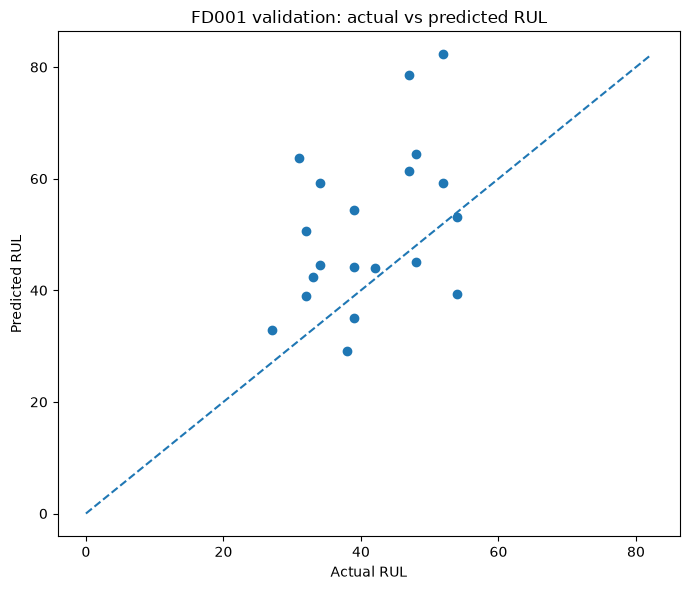

In [9]:
plt.figure(figsize=(7, 6))
plt.scatter(val_results["true_RUL"], val_results["predicted_RUL"])
max_value = max(
    val_results["true_RUL"].max(),
    val_results["predicted_RUL"].max(),
)
plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("FD001 validation: actual vs predicted RUL")
plt.tight_layout()
plt.show()


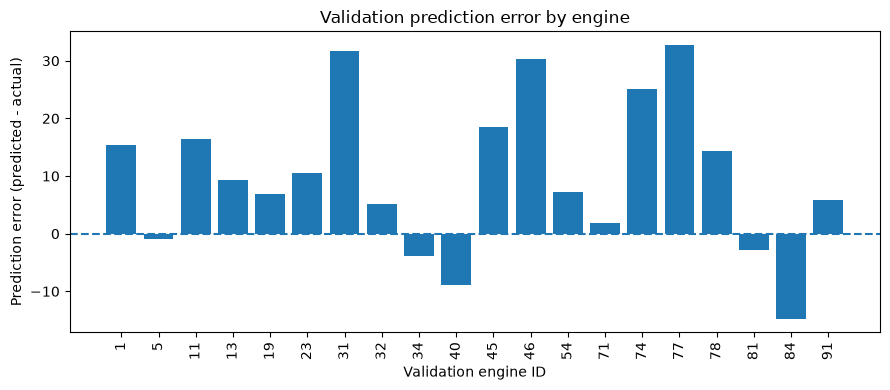

In [10]:
plt.figure(figsize=(9, 4))
ordered = val_results.sort_values("engine_id")
plt.bar(ordered["engine_id"].astype(str), ordered["error"])
plt.axhline(0, linestyle="--")
plt.xlabel("Validation engine ID")
plt.ylabel("Prediction error (predicted - actual)")
plt.title("Validation prediction error by engine")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


## 9. Feature importance

Feature importance is a model diagnostic, not evidence that a sensor causes degradation.

,feature,importance
0,cycle,0.580352
1,sensor_11,0.168468
2,sensor_9,0.046273
3,sensor_4,0.045895
4,sensor_12,0.020917
5,sensor_7,0.019545
6,sensor_14,0.019465
7,sensor_15,0.016299
8,sensor_21,0.012406
9,sensor_3,0.011509


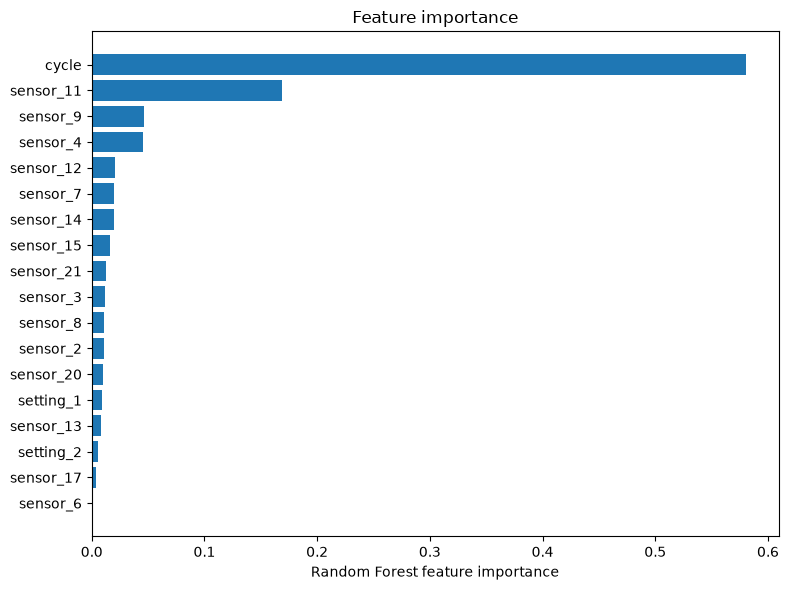

In [11]:
importance_df = (
    pd.DataFrame({
        "feature": feature_columns,
        "importance": model.feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
display(importance_df)

plt.figure(figsize=(8, 6))
plot_df = importance_df.sort_values("importance")
plt.barh(plot_df["feature"], plot_df["importance"])
plt.xlabel("Random Forest feature importance")
plt.title("Feature importance")
plt.tight_layout()
plt.show()


## 10. Save the baseline artifacts

Save the trained model, feature list, and metrics so later application code can load the same configuration. These files are written to `models/` and `reports/` in the project root.

In [12]:
import json
import joblib

MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "fd001_random_forest_cap150.joblib"
joblib.dump(model, model_path)

metrics = {
    "dataset": "NASA C-MAPSS FD001",
    "model": "RandomForestRegressor",
    "n_estimators": 200,
    "random_state": RANDOM_STATE,
    "min_samples_leaf": 2,
    "rul_cap": RUL_CAP,
    "observation_fraction": OBSERVATION_FRACTION,
    "n_training_engines": int(len(train_engine_ids)),
    "n_validation_engines": int(len(val_engine_ids)),
    "mae": float(mae),
    "rmse": float(rmse),
    "mean_signed_error": float(bias),
    "features": feature_columns,
}

metrics_path = REPORT_DIR / "fd001_baseline_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
val_results.to_csv(REPORT_DIR / "fd001_validation_predictions.csv", index=False)

print("Saved model:", model_path)
print("Saved metrics:", metrics_path)
print("Saved validation predictions:", REPORT_DIR / "fd001_validation_predictions.csv")


Saved model: /home/rupali-jha/machine-life-predictor/models/fd001_random_forest_cap150.joblib
Saved metrics: /home/rupali-jha/machine-life-predictor/reports/fd001_baseline_metrics.json
Saved validation predictions: /home/rupali-jha/machine-life-predictor/reports/fd001_validation_predictions.csv


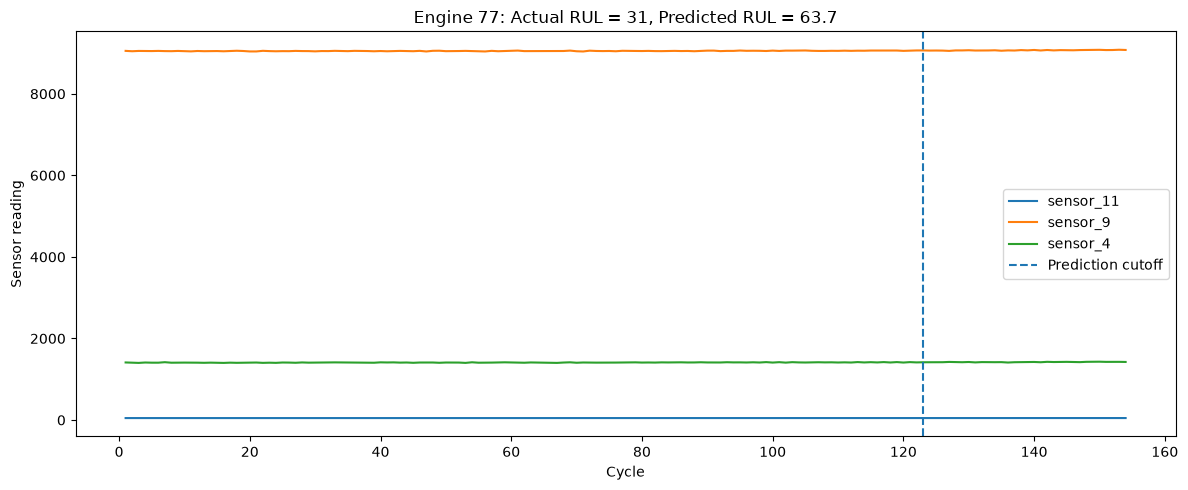

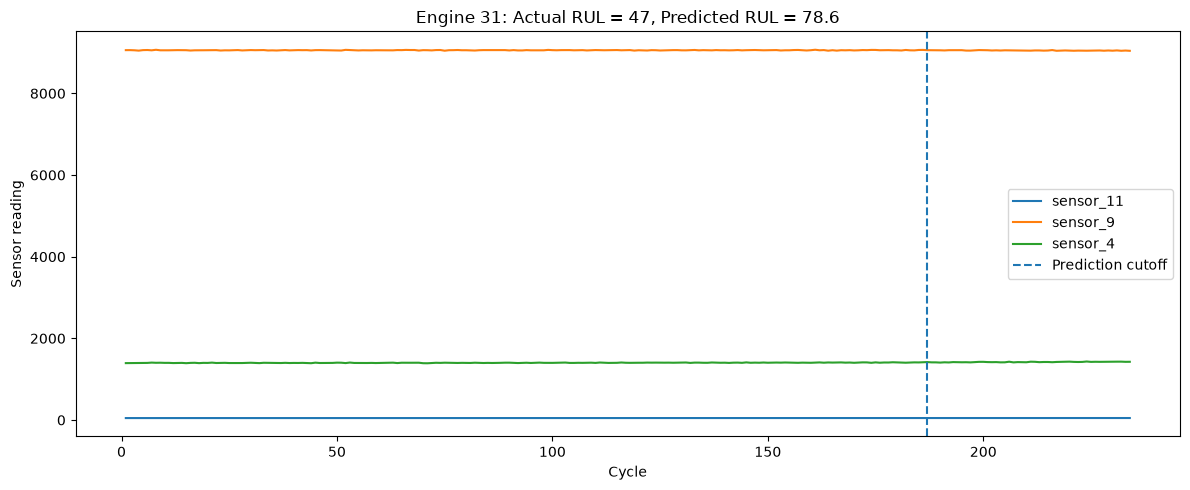

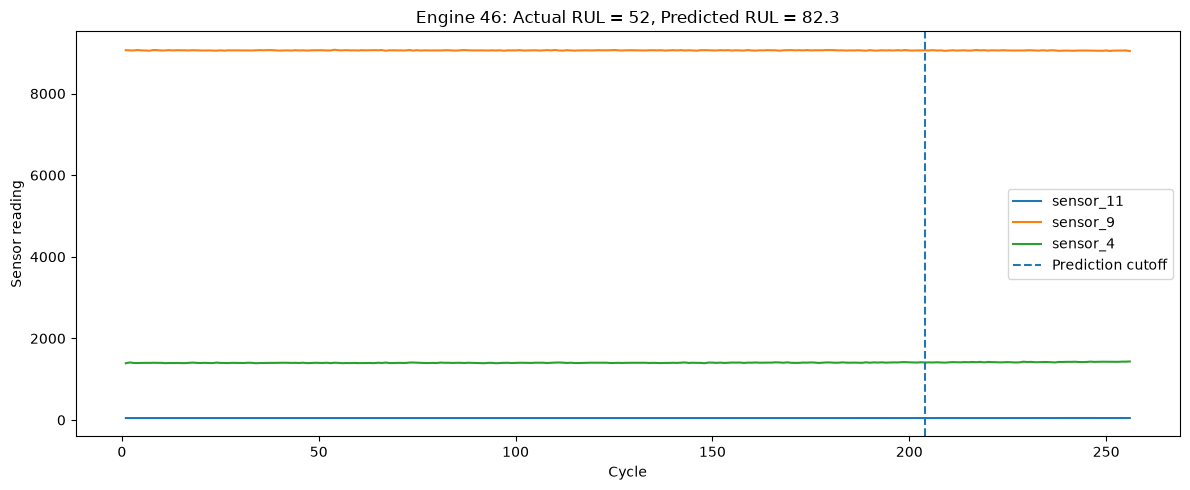

In [13]:
# Investigate engines with the largest prediction errors

engines_to_investigate = [77, 31, 46]

for engine_id in engines_to_investigate:
    engine_data = (
        val_df[val_df["engine_id"] == engine_id]
        .sort_values("cycle")
    )

    prediction_row = val_results[
        val_results["engine_id"] == engine_id
    ].iloc[0]

    plt.figure(figsize=(12, 5))

    for sensor in ["sensor_11", "sensor_9", "sensor_4"]:
        plt.plot(
            engine_data["cycle"],
            engine_data[sensor],
            label=sensor
        )

    cutoff_cycle = prediction_row["cutoff_cycle"]
    plt.axvline(
        cutoff_cycle,
        linestyle="--",
        label="Prediction cutoff"
    )

    plt.xlabel("Cycle")
    plt.ylabel("Sensor reading")
    plt.title(
        f"Engine {engine_id}: "
        f"Actual RUL = {prediction_row['true_RUL']:.0f}, "
        f"Predicted RUL = {prediction_row['predicted_RUL']:.1f}"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()


Engine 77
Actual RUL: 31.0
Predicted RUL: 63.7
Prediction error: +32.73

sensor_11
  First reading: 47.5500
  Last reading:  47.7400
  Minimum:       47.2500
  Maximum:       48.0000
  Standard deviation: 0.1394


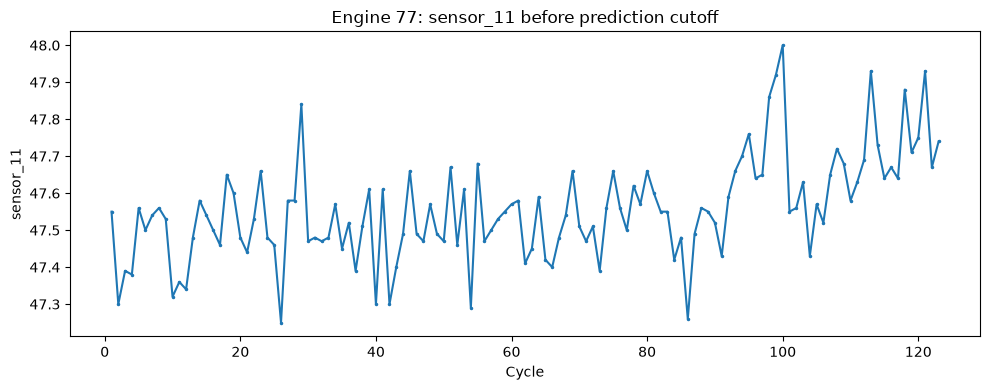


sensor_9
  First reading: 9052.5700
  Last reading:  9063.4900
  Minimum:       9037.9100
  Maximum:       9063.4900
  Standard deviation: 5.7887


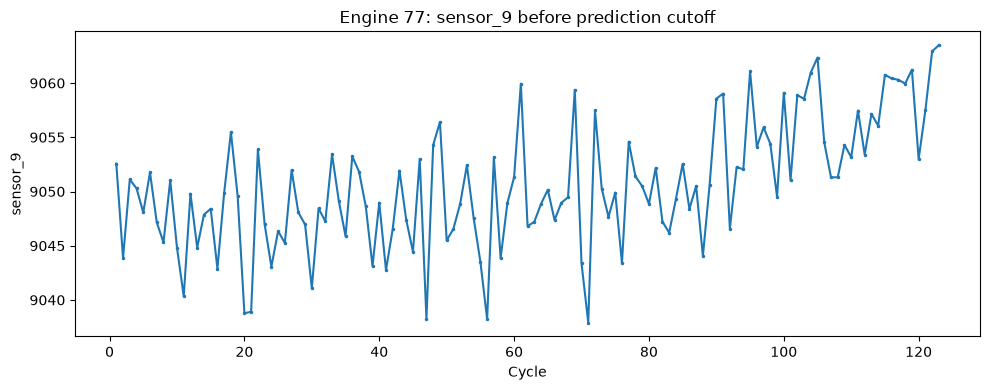


sensor_4
  First reading: 1411.3200
  Last reading:  1416.1000
  Minimum:       1400.2900
  Maximum:       1420.6700
  Standard deviation: 4.6027


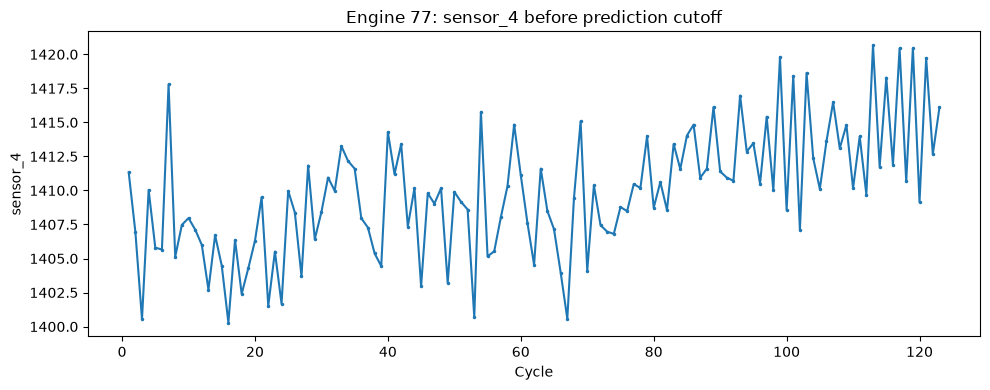


Engine 31
Actual RUL: 47.0
Predicted RUL: 78.6
Prediction error: +31.62

sensor_11
  First reading: 47.1900
  Last reading:  47.5800
  Minimum:       47.0100
  Maximum:       47.7400
  Standard deviation: 0.1562


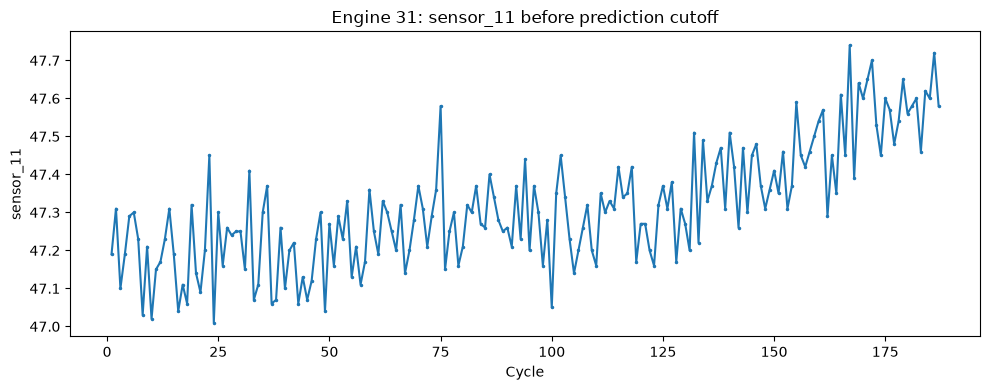


sensor_9
  First reading: 9058.6800
  Last reading:  9058.0600
  Minimum:       9044.8300
  Maximum:       9068.4100
  Standard deviation: 4.1140


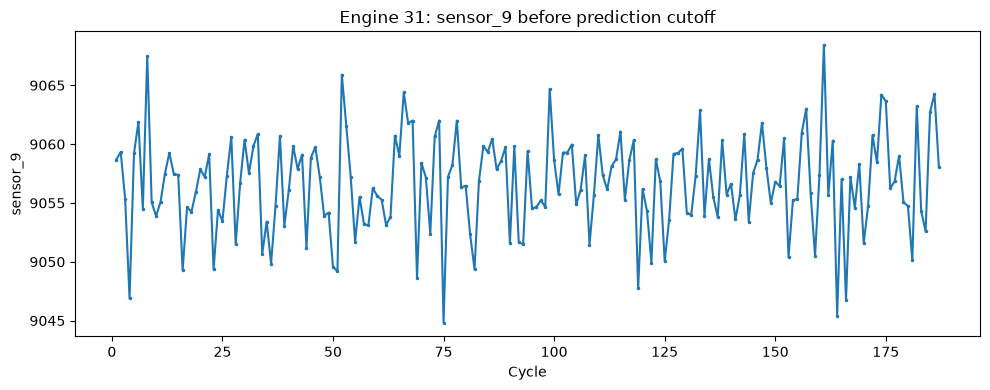


sensor_4
  First reading: 1393.0300
  Last reading:  1418.8200
  Minimum:       1389.5900
  Maximum:       1418.8200
  Standard deviation: 5.0065


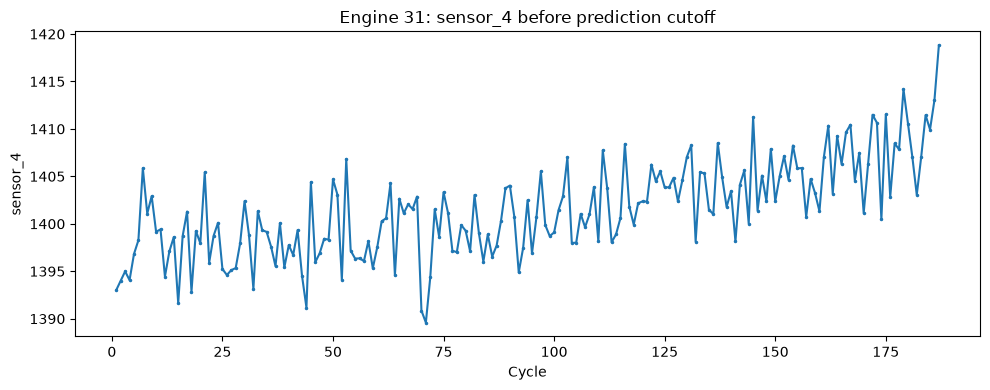


Engine 46
Actual RUL: 52.0
Predicted RUL: 82.3
Prediction error: +30.29

sensor_11
  First reading: 47.2000
  Last reading:  47.6700
  Minimum:       46.9700
  Maximum:       47.7300
  Standard deviation: 0.1675


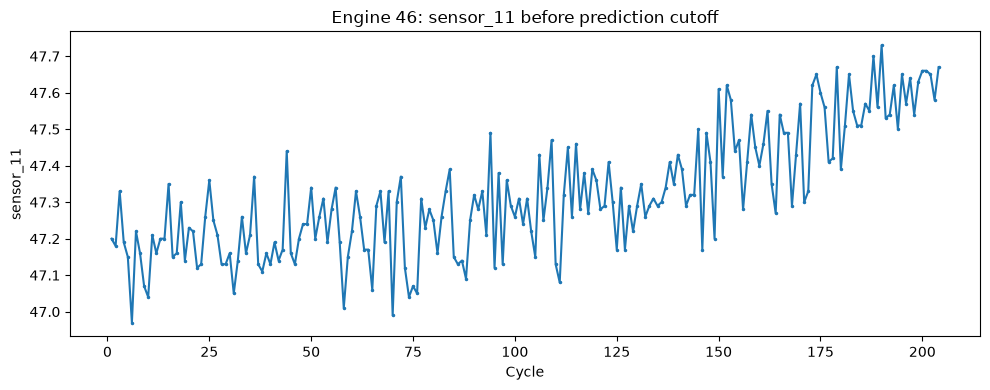


sensor_9
  First reading: 9063.0400
  Last reading:  9059.2500
  Minimum:       9049.3200
  Maximum:       9073.8200
  Standard deviation: 4.0817


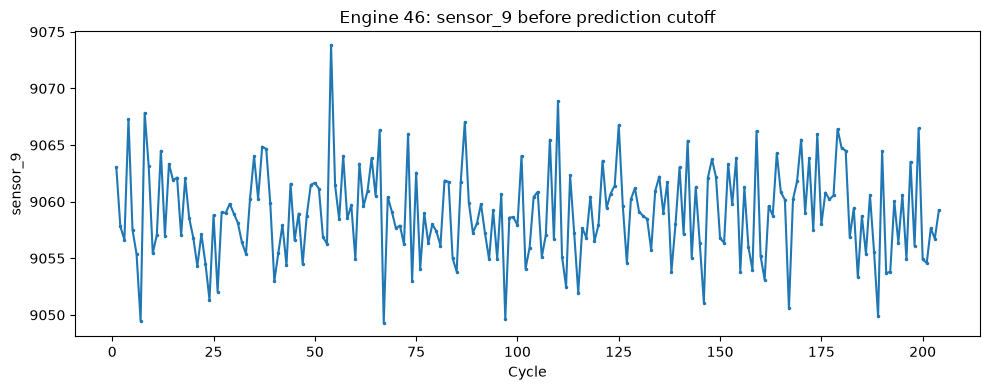


sensor_4
  First reading: 1391.3700
  Last reading:  1408.6900
  Minimum:       1390.8200
  Maximum:       1418.3900
  Standard deviation: 5.3197


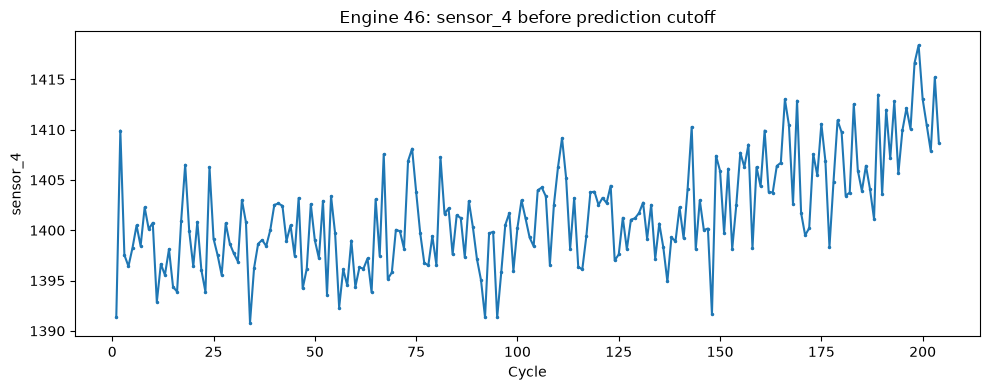

In [14]:
# Investigate sensor variation before the prediction cutoff

engines_to_investigate = [77, 31, 46]
sensors_to_investigate = ["sensor_11", "sensor_9", "sensor_4"]

for engine_id in engines_to_investigate:

    engine_data = (
        val_df[val_df["engine_id"] == engine_id]
        .sort_values("cycle")
    )

    result = val_results[
        val_results["engine_id"] == engine_id
    ].iloc[0]

    cutoff_cycle = int(result["cutoff_cycle"])
    observed_data = engine_data[
        engine_data["cycle"] <= cutoff_cycle
    ]

    print(f"\n{'=' * 60}")
    print(f"Engine {engine_id}")
    print(f"Actual RUL: {result['true_RUL']:.1f}")
    print(f"Predicted RUL: {result['predicted_RUL']:.1f}")
    print(f"Prediction error: {result['error']:+.2f}")
    print(f"{'=' * 60}")

    for sensor in sensors_to_investigate:
        values = observed_data[sensor]

        print(f"\n{sensor}")
        print(f"  First reading: {values.iloc[0]:.4f}")
        print(f"  Last reading:  {values.iloc[-1]:.4f}")
        print(f"  Minimum:       {values.min():.4f}")
        print(f"  Maximum:       {values.max():.4f}")
        print(f"  Standard deviation: {values.std():.4f}")

        plt.figure(figsize=(10, 4))
        plt.plot(
            observed_data["cycle"],
            values,
            marker=".",
            markersize=3
        )
        plt.xlabel("Cycle")
        plt.ylabel(sensor)
        plt.title(f"Engine {engine_id}: {sensor} before prediction cutoff")
        plt.tight_layout()
        plt.show()

In [15]:
# Compare feature values for the three high-error engines

engines_to_investigate = [77, 31, 46]

for engine_id in engines_to_investigate:

    result = val_results[
        val_results["engine_id"] == engine_id
    ].iloc[0]

    engine_data = (
        val_df[val_df["engine_id"] == engine_id]
        .sort_values("cycle")
    )

    cutoff_row = engine_data[
        engine_data["cycle"] == result["cutoff_cycle"]
    ].iloc[-1]

    print(f"\n{'=' * 55}")
    print(f"Engine: {engine_id}")
    print(f"Actual RUL: {result['true_RUL']:.1f}")
    print(f"Predicted RUL: {result['predicted_RUL']:.1f}")
    print(f"Prediction error: {result['error']:+.2f}")
    print("\nSensor readings at prediction time:")

    for sensor in ["sensor_11", "sensor_9", "sensor_4"]:
        print(f"{sensor}: {cutoff_row[sensor]:.4f}")

    print(f"Cycle: {cutoff_row['cycle']}")


Engine: 77
Actual RUL: 31.0
Predicted RUL: 63.7
Prediction error: +32.73

Sensor readings at prediction time:
sensor_11: 47.7400
sensor_9: 9063.4900
sensor_4: 1416.1000
Cycle: 123.0

Engine: 31
Actual RUL: 47.0
Predicted RUL: 78.6
Prediction error: +31.62

Sensor readings at prediction time:
sensor_11: 47.5800
sensor_9: 9058.0600
sensor_4: 1418.8200
Cycle: 187.0

Engine: 46
Actual RUL: 52.0
Predicted RUL: 82.3
Prediction error: +30.29

Sensor readings at prediction time:
sensor_11: 47.6700
sensor_9: 9059.2500
sensor_4: 1408.6900
Cycle: 204.0


In [16]:
# Create temporal features without using future observations

temporal_df = train_df.sort_values(
    ["engine_id", "cycle"]
).copy()

sensors = ["sensor_11", "sensor_9"]

for sensor in sensors:
    grouped = temporal_df.groupby("engine_id")[sensor]

    # Mean over the current and previous four observations
    temporal_df[f"{sensor}_rolling_mean_5"] = (
        grouped.transform(
            lambda s: s.rolling(window=5, min_periods=1).mean()
        )
    )

    # Standard deviation over the current and previous four observations
    temporal_df[f"{sensor}_rolling_std_5"] = (
        grouped.transform(
            lambda s: s.rolling(window=5, min_periods=2).std()
        ).fillna(0)
    )

    # Difference from five observations earlier
    temporal_df[f"{sensor}_diff_5"] = (
        grouped.diff(periods=5).fillna(0)
    )

new_temporal_features = [
    f"{sensor}_{suffix}"
    for sensor in sensors
    for suffix in [
        "rolling_mean_5",
        "rolling_std_5",
        "diff_5",
    ]
]

print("New temporal features:")
print(new_temporal_features)

display(
    temporal_df[
        ["engine_id", "cycle", "sensor_11"]
        + new_temporal_features
    ].head(10)
)

New temporal features:
['sensor_11_rolling_mean_5', 'sensor_11_rolling_std_5', 'sensor_11_diff_5', 'sensor_9_rolling_mean_5', 'sensor_9_rolling_std_5', 'sensor_9_diff_5']


,engine_id,cycle,sensor_11,sensor_11_rolling_mean_5,sensor_11_rolling_std_5,sensor_11_diff_5,sensor_9_rolling_mean_5,sensor_9_rolling_std_5,sensor_9_diff_5
0,1,1,47.47,47.470,0.000000,0.00,9046.190000,0.000000,0.00
1,1,2,47.49,47.480,0.014142,0.00,9045.130000,1.499066,0.00
2,1,3,47.27,47.410,0.121655,0.00,9047.733333,4.632023,0.00
3,1,4,47.13,47.340,0.171659,0.00,9048.170000,3.881555,0.00
4,1,5,47.28,47.328,0.151063,0.00,9049.566000,4.587366,0.00
5,1,6,47.16,47.266,0.141527,-0.31,9050.264000,4.193904,3.49
6,1,7,47.36,47.240,0.094074,-0.13,9053.276000,4.038407,15.06
7,1,8,47.24,47.234,0.092628,-0.03,9050.848000,6.915502,-12.14
8,1,9,47.29,47.266,0.073348,0.16,9050.244000,7.191240,-3.02
9,1,10,47.03,47.216,0.127004,-0.25,9049.554000,6.755115,-3.45


In [18]:
# Compare the baseline and temporal-feature models

temporal_feature_columns = (
    feature_columns + new_temporal_features
)

temporal_train_mask = temporal_df["engine_id"].isin(
    train_engine_ids
)

temporal_val_mask = temporal_df["engine_id"].isin(
    val_engine_ids
)

X_train_temporal = temporal_df.loc[
    temporal_train_mask, temporal_feature_columns
]

y_train_temporal = temporal_df.loc[
    temporal_train_mask, "RUL_capped"
]

temporal_val_df = temporal_df.loc[
    temporal_val_mask
].copy()

temporal_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    min_samples_leaf=2,
)

temporal_model.fit(
    X_train_temporal,
    y_train_temporal
)

temporal_results = make_cutoff_evaluation(
    full_data=temporal_val_df,
    heldout_engine_ids=val_engine_ids,
    feature_cols=temporal_feature_columns,
    fitted_model=temporal_model,
    observation_fraction=OBSERVATION_FRACTION,
)

temporal_mae = mean_absolute_error(
    temporal_results["true_RUL"],
    temporal_results["predicted_RUL"]
)

temporal_rmse = mean_squared_error(
    temporal_results["true_RUL"],
    temporal_results["predicted_RUL"]
) ** 0.5

temporal_bias = temporal_results["error"].mean()

comparison = pd.DataFrame([
    {
        "Model": "Baseline",
        "MAE": mae,
        "RMSE": rmse,
        "Mean signed error": bias,
    },
    {
        "Model": "Temporal features",
        "MAE": temporal_mae,
        "RMSE": temporal_rmse,
        "Mean signed error": temporal_bias,
    },
])

display(comparison.round(2))

,Model,MAE,RMSE,Mean signed error
0,Baseline,13.14,16.38,10.01
1,Temporal features,14.26,17.67,9.50


In [19]:
# Analyze prediction errors across all validation engines

error_thresholds = [5, 10, 20]

print(f"Total validation engines: {len(val_results)}")
print()

for threshold in error_thresholds:
    within_threshold = (
        val_results["absolute_error"] <= threshold
    ).sum()

    outside_threshold = len(val_results) - within_threshold
    percentage = within_threshold / len(val_results) * 100

    print(f"Error threshold: {threshold} cycles")
    print(f"  Within threshold: {within_threshold}/20 ({percentage:.1f}%)")
    print(f"  Outside threshold: {outside_threshold}/20")
    print()

Total validation engines: 20

Error threshold: 5 cycles
  Within threshold: 4/20 (20.0%)
  Outside threshold: 16/20

Error threshold: 10 cycles
  Within threshold: 10/20 (50.0%)
  Outside threshold: 10/20

Error threshold: 20 cycles
  Within threshold: 16/20 (80.0%)
  Outside threshold: 4/20



In [20]:
# Sort engines by absolute prediction error

error_analysis = val_results[
    [
        "engine_id",
        "true_RUL",
        "predicted_RUL",
        "error",
        "absolute_error",
    ]
].sort_values(
    "absolute_error",
    ascending=False
)

display(error_analysis.round(2))

,engine_id,true_RUL,predicted_RUL,error,absolute_error
16,77,31.0,63.73,32.73,32.73
11,31,47.0,78.62,31.62,31.62
3,46,52.0,82.29,30.29,30.29
12,74,34.0,59.16,25.16,25.16
4,45,32.0,50.55,18.55,18.55
8,11,48.0,64.48,16.48,16.48
9,1,39.0,54.45,15.45,15.45
0,84,54.0,39.25,-14.75,14.75
17,78,47.0,61.32,14.32,14.32
6,23,34.0,44.48,10.48,10.48


In [21]:

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Train Gradient Boosting using the same training data
gb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [23]:

gb_results = make_cutoff_evaluation(
    full_data=val_df,
    heldout_engine_ids=val_engine_ids,
    feature_cols=feature_columns,
    fitted_model=gb_model,
    observation_fraction=OBSERVATION_FRACTION
)

gb_mae = mean_absolute_error(
    gb_results["true_RUL"],
    gb_results["predicted_RUL"]
)

gb_rmse = mean_squared_error(
    gb_results["true_RUL"],
    gb_results["predicted_RUL"]
) ** 0.5

gb_bias = gb_results["error"].mean()

print(f"MAE: {gb_mae:.2f}")
print(f"RMSE: {gb_rmse:.2f}")
print(f"Mean signed error: {gb_bias:+.2f}")


MAE: 12.94
RMSE: 15.71
Mean signed error: +8.12


In [24]:

comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE": mae,
        "RMSE": rmse,
        "Mean signed error": bias
    },
    {
        "Model": "HistGradientBoosting",
        "MAE": gb_mae,
        "RMSE": gb_rmse,
        "Mean signed error": gb_bias
    }
])

display(comparison.round(2))


,Model,MAE,RMSE,Mean signed error
0,Random Forest,13.14,16.38,10.01
1,HistGradientBoosting,12.94,15.71,8.12


In [25]:
import time
from sklearn.ensemble import HistGradientBoostingRegressor

gb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

start_time = time.perf_counter()

gb_model.fit(X_train, y_train)

training_time = time.perf_counter() - start_time

print(f"Training time: {training_time:.4f} seconds")
print(f"Configured maximum iterations: {gb_model.max_iter}")
print(f"Iterations performed: {gb_model.n_iter_}")
print(f"Training observations: {len(X_train)}")
print(f"Number of features: {X_train.shape[1]}")

Training time: 0.2431 seconds
Configured maximum iterations: 200
Iterations performed: 100
Training observations: 16561
Number of features: 18


In [26]:
print("Early stopping enabled:", gb_model.early_stopping)
print("Early stopping actually used:", gb_model.do_early_stopping_)
print("Iterations performed:", gb_model.n_iter_)
print("Maximum iterations:", gb_model.max_iter)

print("Validation fraction:", gb_model.validation_fraction)
print("Early stopping patience:", gb_model.n_iter_no_change)
print("Minimum improvement:", gb_model.tol)

Early stopping enabled: auto
Early stopping actually used: True
Iterations performed: 100
Maximum iterations: 200
Validation fraction: 0.1
Early stopping patience: 10
Minimum improvement: 1e-07


In [27]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

results = []

# Use five different engine-level splits
for seed in [42, 21, 7, 100, 2026]:

    # Split unique engine IDs, not individual rows
    engine_ids = train_df["engine_id"].unique()

    train_ids, val_ids = train_test_split(
        engine_ids,
        test_size=0.20,
        random_state=seed
    )

    train_data = train_df[train_df["engine_id"].isin(train_ids)]
    val_data = train_df[train_df["engine_id"].isin(val_ids)]

    X_train_split = train_data[feature_columns]
    y_train_split = train_data["RUL_capped"]

    # Train Random Forest
    rf = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    )

    rf.fit(X_train_split, y_train_split)

    rf_results = make_cutoff_evaluation(
        full_data=val_data,
        heldout_engine_ids=val_ids,
        feature_cols=feature_columns,
        fitted_model=rf,
        observation_fraction=OBSERVATION_FRACTION
    )

    # Train Gradient Boosting
    gb = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )

    gb.fit(X_train_split, y_train_split)

    gb_results = make_cutoff_evaluation(
        full_data=val_data,
        heldout_engine_ids=val_ids,
        feature_cols=feature_columns,
        fitted_model=gb,
        observation_fraction=OBSERVATION_FRACTION
    )

    # Record results
    for model_name, predictions in [
        ("Random Forest", rf_results),
        ("HistGradientBoosting", gb_results)
    ]:
        results.append({
            "seed": seed,
            "model": model_name,
            "MAE": mean_absolute_error(
                predictions["true_RUL"],
                predictions["predicted_RUL"]
            ),
            "RMSE": mean_squared_error(
                predictions["true_RUL"],
                predictions["predicted_RUL"]
            ) ** 0.5,
            "Bias": predictions["error"].mean()
        })

results_df = pd.DataFrame(results)

display(results_df.round(2))

,seed,model,MAE,RMSE,Bias
0,42,Random Forest,13.14,16.38,10.01
1,42,HistGradientBoosting,12.94,15.71,8.12
2,21,Random Forest,15.32,19.06,11.25
3,21,HistGradientBoosting,13.77,17.51,9.93
4,7,Random Forest,12.40,15.67,6.80
5,7,HistGradientBoosting,12.76,16.64,6.25
6,100,Random Forest,14.73,20.47,7.50
7,100,HistGradientBoosting,13.48,18.34,5.26
8,2026,Random Forest,17.49,23.84,12.91
9,2026,HistGradientBoosting,17.61,22.65,10.74


In [28]:
summary = results_df.groupby("model").agg(
    mean_MAE=("MAE", "mean"),
    std_MAE=("MAE", "std"),
    mean_RMSE=("RMSE", "mean"),
    std_RMSE=("RMSE", "std"),
    mean_Bias=("Bias", "mean")
).round(2)

display(summary)

,mean_MAE,std_MAE,mean_RMSE,std_RMSE,mean_Bias
model,,,,,
HistGradientBoosting,14.11,2.00,18.17,2.69,8.06
Random Forest,14.62,1.99,19.08,3.30,9.69


In [29]:
# Evaluate HistGradientBoosting at different observation cutoffs

cutoffs = [0.60, 0.70, 0.80, 0.90]
cutoff_results = []

# Use the same validation engines from the five-split experiment
# Choose seed 42 as a reproducible evaluation split.
engine_ids = train_df["engine_id"].unique()

train_ids, val_ids = train_test_split(
    engine_ids,
    test_size=0.20,
    random_state=42
)

train_data = train_df[train_df["engine_id"].isin(train_ids)]
val_data = train_df[train_df["engine_id"].isin(val_ids)]

X_train_cutoff = train_data[feature_columns]
y_train_cutoff = train_data["RUL_capped"]

# Train the model once; evaluate it at each cutoff
gb_cutoff_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gb_cutoff_model.fit(X_train_cutoff, y_train_cutoff)

for cutoff in cutoffs:

    predictions = make_cutoff_evaluation(
        full_data=val_data,
        heldout_engine_ids=val_ids,
        feature_cols=feature_columns,
        fitted_model=gb_cutoff_model,
        observation_fraction=cutoff
    )

    cutoff_results.append({
        "Observation cutoff": f"{cutoff:.0%}",
        "MAE": mean_absolute_error(
            predictions["true_RUL"],
            predictions["predicted_RUL"]
        ),
        "RMSE": mean_squared_error(
            predictions["true_RUL"],
            predictions["predicted_RUL"]
        ) ** 0.5,
        "Mean signed error": predictions["error"].mean()
    })

cutoff_df = pd.DataFrame(cutoff_results)

display(cutoff_df.round(2))

,Observation cutoff,MAE,RMSE,Mean signed error
0,60%,20.84,26.05,10.79
1,70%,19.76,23.80,11.53
2,80%,12.94,15.71,8.12
3,90%,6.95,9.34,3.48


In [30]:
# Evaluate HistGradientBoosting across 5 splits and 4 cutoffs

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

seeds = [42, 21, 7, 100, 2026]
cutoffs = [0.60, 0.70, 0.80, 0.90]

robust_results = []

for seed in seeds:

    # Split by engine ID to prevent engine leakage
    engine_ids = train_df["engine_id"].unique()

    train_ids, val_ids = train_test_split(
        engine_ids,
        test_size=0.20,
        random_state=seed
    )

    train_data = train_df[
        train_df["engine_id"].isin(train_ids)
    ]

    val_data = train_df[
        train_df["engine_id"].isin(val_ids)
    ]

    X_train_split = train_data[feature_columns]
    y_train_split = train_data["RUL_capped"]

    # Train one model for this split
    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )

    model.fit(X_train_split, y_train_split)

    # Evaluate at each observation cutoff
    for cutoff in cutoffs:

        predictions = make_cutoff_evaluation(
            full_data=val_data,
            heldout_engine_ids=val_ids,
            feature_cols=feature_columns,
            fitted_model=model,
            observation_fraction=cutoff
        )

        robust_results.append({
            "seed": seed,
            "cutoff": f"{cutoff:.0%}",
            "MAE": mean_absolute_error(
                predictions["true_RUL"],
                predictions["predicted_RUL"]
            ),
            "RMSE": mean_squared_error(
                predictions["true_RUL"],
                predictions["predicted_RUL"]
            ) ** 0.5,
            "Bias": predictions["error"].mean()
        })

robust_df = pd.DataFrame(robust_results)

display(robust_df.round(2))

,seed,cutoff,MAE,RMSE,Bias
0,42,60%,20.84,26.05,10.79
1,42,70%,19.76,23.80,11.53
2,42,80%,12.94,15.71,8.12
3,42,90%,6.95,9.34,3.48
4,21,60%,23.04,27.79,4.98
5,21,70%,17.39,23.03,6.15
6,21,80%,13.77,17.51,9.93
7,21,90%,6.11,8.02,2.43
8,7,60%,15.76,20.44,-0.61
9,7,70%,12.16,15.64,-2.32


In [31]:
cutoff_summary = robust_df.groupby("cutoff").agg(
    mean_MAE=("MAE", "mean"),
    std_MAE=("MAE", "std"),
    mean_RMSE=("RMSE", "mean"),
    std_RMSE=("RMSE", "std"),
    mean_Bias=("Bias", "mean")
).round(2)

display(cutoff_summary)

,mean_MAE,std_MAE,mean_RMSE,std_RMSE,mean_Bias
cutoff,,,,,
60%,19.09,3.75,23.35,4.28,6.71
70%,17.81,3.57,22.65,4.17,6.64
80%,14.11,2.00,18.17,2.69,8.06
90%,6.53,1.20,8.45,1.44,2.86


In [32]:
display(
    robust_df.pivot(
        index="seed",
        columns="cutoff",
        values="MAE"
    ).round(2)
)

cutoff,60%,70%,80%,90%
seed,,,,
7,15.76,12.16,12.76,4.96
21,23.04,17.39,13.77,6.11
42,20.84,19.76,12.94,6.95
100,21.34,18.03,13.48,8.23
2026,14.48,21.70,17.61,6.37


In [33]:
display(
    robust_df.pivot(
        index="seed",
        columns="cutoff",
        values="MAE"
    ).round(2)
)

cutoff,60%,70%,80%,90%
seed,,,,
7,15.76,12.16,12.76,4.96
21,23.04,17.39,13.77,6.11
42,20.84,19.76,12.94,6.95
100,21.34,18.03,13.48,8.23
2026,14.48,21.70,17.61,6.37


In [34]:
bias_pivot = robust_df.pivot(
    index="seed",
    columns="cutoff",
    values="Bias"
)

display(bias_pivot.round(2))

cutoff,60%,70%,80%,90%
seed,,,,
7,-0.61,-2.32,6.25,2.10
21,4.98,6.15,9.93,2.43
42,10.79,11.53,8.12,3.48
100,11.63,7.56,5.26,4.01
2026,6.79,10.29,10.74,2.29


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

SEED = 42
CUTOFF = 0.80

# 1. Split engines into model-training and validation groups
engine_ids = train_df["engine_id"].unique()

train_ids, val_ids = train_test_split(
    engine_ids,
    test_size=0.20,
    random_state=SEED
)

# 2. Split training engines into model-fitting and calibration groups
fit_ids, calibration_ids = train_test_split(
    train_ids,
    test_size=0.25,
    random_state=SEED
)

fit_data = train_df[train_df["engine_id"].isin(fit_ids)]
calibration_data = train_df[
    train_df["engine_id"].isin(calibration_ids)
]
validation_data = train_df[train_df["engine_id"].isin(val_ids)]

# 3. Fit the model without using calibration or validation engines
model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

model.fit(
    fit_data[feature_columns],
    fit_data["RUL_capped"]
)

# 4. Estimate bias using calibration engines only
calibration_predictions = make_cutoff_evaluation(
    full_data=calibration_data,
    heldout_engine_ids=calibration_ids,
    feature_cols=feature_columns,
    fitted_model=model,
    observation_fraction=CUTOFF
)

calibration_bias = (
    calibration_predictions["predicted_RUL"]
    - calibration_predictions["true_RUL"]
).mean()

print(f"Calibration engines: {len(calibration_ids)}")
print(f"Calibration bias: {calibration_bias:.2f} cycles")

# 5. Evaluate on untouched validation engines
validation_predictions = make_cutoff_evaluation(
    full_data=validation_data,
    heldout_engine_ids=val_ids,
    feature_cols=feature_columns,
    fitted_model=model,
    observation_fraction=CUTOFF
)

actual = validation_predictions["true_RUL"].to_numpy()
predicted = validation_predictions["predicted_RUL"].to_numpy()

# Compare original and bias-corrected predictions
corrected = np.maximum(0, predicted - calibration_bias)

results = pd.DataFrame({
    "Model": ["Original", "Bias-corrected"],
    "MAE": [
        mean_absolute_error(actual, predicted),
        mean_absolute_error(actual, corrected)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, predicted)),
        np.sqrt(mean_squared_error(actual, corrected))
    ],
    "Bias": [
        np.mean(predicted - actual),
        np.mean(corrected - actual)
    ]
})

display(results.round(2))

Calibration engines: 20
Calibration bias: 20.73 cycles


,Model,MAE,RMSE,Bias
0,Original,17.61,22.50,12.31
1,Bias-corrected,17.41,20.63,-8.43


In [36]:
error_analysis = validation_predictions.copy()

error_analysis["error"] = (
    error_analysis["predicted_RUL"]
    - error_analysis["true_RUL"]
)

error_analysis["absolute_error"] = error_analysis["error"].abs()

error_analysis = error_analysis.sort_values(
    "error",
    ascending=False
)

display(
    error_analysis[
        ["engine_id", "true_RUL", "predicted_RUL", "error", "absolute_error"]
    ].round(2)
)

,engine_id,true_RUL,predicted_RUL,error,absolute_error
14,91,27.0,79.04,52.04,52.04
11,31,47.0,86.49,39.49,39.49
3,46,52.0,88.46,36.46,36.46
12,74,34.0,66.85,32.85,32.85
16,77,31.0,60.24,29.24,29.24
6,23,34.0,57.84,23.84,23.84
17,78,47.0,68.04,21.04,21.04
4,45,32.0,50.44,18.44,18.44
10,19,32.0,49.15,17.15,17.15
9,1,39.0,54.24,15.24,15.24


In [37]:
# Engines with the five largest overestimates
worst_engines = [91, 31, 46, 74, 77]

cutoff = 0.80
sensor_cols = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_14",
    "sensor_15",
]

sensor_comparison = []

for engine_id in worst_engines:
    engine_data = (
        validation_data[
            validation_data["engine_id"] == engine_id
        ]
        .sort_values("cycle")
    )

    # Observe only the first 80% of the engine's trajectory
    n_observed = max(1, int(np.floor(len(engine_data) * cutoff)))
    observed = engine_data.iloc[:n_observed]

    row = {
        "engine_id": engine_id,
        "observed_cycles": len(observed),
        "last_observed_cycle": observed["cycle"].iloc[-1],
    }

    # Mean sensor readings over the observed portion
    for sensor in sensor_cols:
        row[sensor] = observed[sensor].mean()

    sensor_comparison.append(row)

sensor_comparison_df = pd.DataFrame(sensor_comparison)

display(sensor_comparison_df.round(3))

,engine_id,observed_cycles,last_observed_cycle,sensor_2,sensor_3,sensor_4,sensor_7,sensor_9,sensor_11,sensor_12,sensor_14,sensor_15
0,91,108,108,642.918,1592.832,1414.030,552.854,9053.742,47.688,521.017,8131.849,8.461
1,31,187,187,642.315,1586.143,1401.469,554.116,9056.637,47.312,522.018,8138.406,8.413
2,46,204,204,642.290,1586.236,1401.591,554.099,9058.989,47.319,522.016,8140.104,8.414
3,74,132,132,642.394,1588.167,1403.982,553.869,9065.688,47.397,521.802,8145.553,8.423
4,77,123,123,642.734,1589.880,1409.864,553.255,9050.555,47.554,521.353,8130.098,8.443
